# Листок № 2. Комплексные числа и их геометрия

Решения заданий 2.1–2.10 по листку П. Е. Рябова. В конце листка номер 2.10 напечатан дважды. Ниже выполнены оба задания, включая логарифмическую спираль. Разделения на индивидуальные варианты в листке нет.

In [1]:
%matplotlib inline
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.special import loggamma
from IPython.display import Math, display
from matplotlib.colors import ListedColormap

INK = "#18655e"
ACCENT = "#9a462b"
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlepad": 9})

def plane(ax, title):
    ax.set(title=title, xlabel=r"$\operatorname{Re}z$",
           ylabel=r"$\operatorname{Im}z$", aspect="equal")
    ax.axhline(0, color="#7b8490", lw=0.7, zorder=1)
    ax.axvline(0, color="#7b8490", lw=0.7, zorder=1)
    ax.grid(alpha=0.20)

def complex_text(z, digits=8):
    return f"{z.real:.{digits}f}{z.imag:+.{digits}f}i"

def nth_roots(w, n):
    angles = (np.angle(w) + 2*np.pi*np.arange(n))/n
    return abs(w)**(1/n) * np.exp(1j*angles)

def draw_roots(ax, roots, title):
    plane(ax, title)
    ax.scatter(roots.real, roots.imag, s=32, color=INK, zorder=3)
    for k, z in enumerate(roots):
        ax.annotate(str(k), (z.real, z.imag), xytext=(5, 5),
                    textcoords="offset points", fontsize=8)
    ax.margins(0.23)

## 2.1. Три формы записи

Для ненулевого числа $z=x+iy$ модуль $r=\sqrt{x^2+y^2}$, а главный аргумент $\varphi=\operatorname{atan2}(y,x)$. Подставляем найденные $r$ и $\varphi$ в $r(\cos\varphi+i\sin\varphi)$ и $re^{i\varphi}$.

In [2]:
i = sp.I
expressions = [
    (5+i)*(7-6*i)/(3+i),
    (1+i)**5/(1-i)**3,
    (-1+i*sp.sqrt(3))**15/(1-i)**20 + (-1-i*sp.sqrt(3))**15/(1+i)**20,
]
for label, expression in zip("abc", expressions):
    z = sp.simplify(sp.expand_complex(expression))
    r, phi = sp.simplify(abs(z)), sp.arg(z)
    z_tex, r_tex, phi_tex = map(sp.latex, (z, r, phi))
    display(Math(
        rf"({label})\quad {z_tex} = "
        rf"{r_tex}\left(\cos\left({phi_tex}\right)+i\sin\left({phi_tex}\right)\right)"
        rf" = {r_tex}e^{{i\left({phi_tex}\right)}}"
    ))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 2.2. Уравнение $z^8=1+i$

У числа $1+i$ модуль $\sqrt2$ и аргумент $\pi/4$. Деление аргумента с учётом всех оборотов даёт
$$
z_k=2^{1/16}\exp\left[i\left(\frac{\pi}{32}+\frac{\pi k}{4}\right)\right],
\qquad k=0,\dots,7.
$$
Корни лежат в вершинах правильного восьмиугольника.

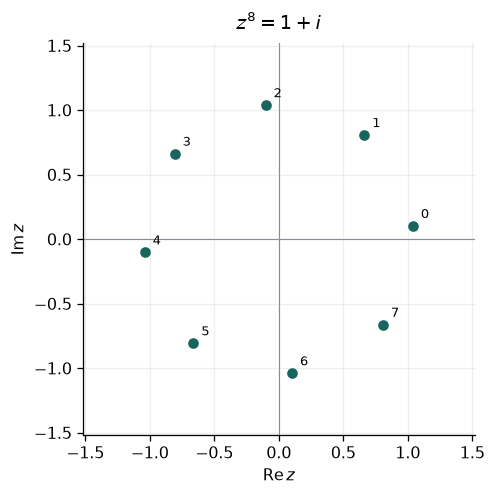

In [3]:
roots = nth_roots(1+1j, 8)
assert np.max(abs(roots**8 - (1+1j))) < 1e-12
fig, ax = plt.subplots(figsize=(4.6, 4.2), layout="constrained")
draw_roots(ax, roots, r"$z^8=1+i$")
plt.show()

## 2.3. Корни на комплексной плоскости

Если $w=Re^{i\varphi}$, то его корни степени $n$ задаются формулой
$z_k=R^{1/n}e^{i(\varphi+2\pi k)/n}$ для $k=0,\ldots,n-1$. По этой формуле находим все корни и проверяем их возведением в степень.

a) n=8, w=1
   1.00000+0.00000i, 0.70711+0.70711i, 0.00000+1.00000i, -0.70711+0.70711i, -1.00000+0.00000i, -0.70711-0.70711i, -0.00000-1.00000i, 0.70711-0.70711i
b) n=4, w=-9/2 + 9*sqrt(3)*I/2
   1.50000+0.86603i, -0.86603+1.50000i, -1.50000-0.86603i, 0.86603-1.50000i
c) n=3, w=9 - 8*I
   2.22516-0.54976i, -0.63648+2.20193i, -1.58869-1.65217i
d) n=9, w=1 - I
   1.03530-0.09058i, 0.85131+0.59609i, 0.26898+1.00385i, -0.43921+0.94189i, -0.94189+0.43921i, -1.00385-0.26898i, -0.59609-0.85131i, 0.09058-1.03530i, 0.73487-0.73487i


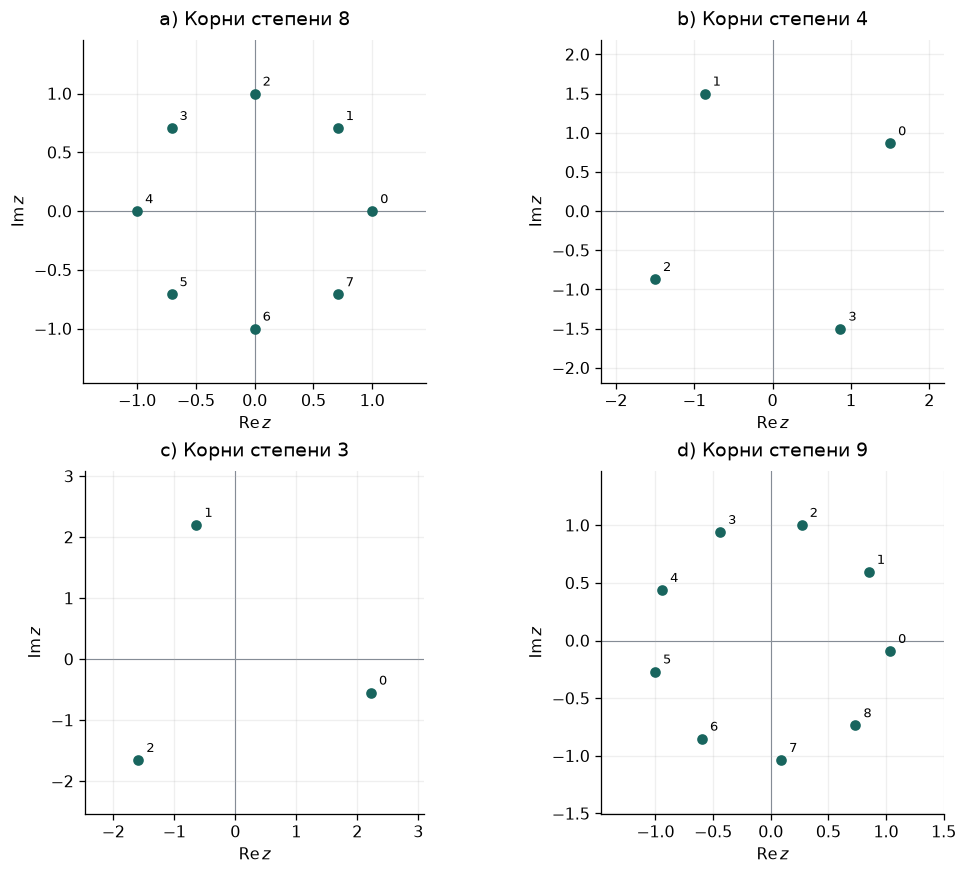

In [4]:
cases = [
    ("a", 8, 1),
    ("b", 4, -18/(1+i*sp.sqrt(3))),
    ("c", 3, (1-5*i)/(1+i)-5*(1+2*i)/(2-i)+11),
    ("d", 9, 1-i),
]
fig, axes = plt.subplots(2, 2, figsize=(9, 7.5), layout="constrained")
for ax, (label, n, expression) in zip(axes.flat, cases):
    reduced = sp.simplify(sp.expand_complex(expression))
    w = complex(reduced)
    roots = nth_roots(w, n)
    print(f"{label}) n={n}, w={reduced}")
    print("   " + ", ".join(complex_text(z, 5) for z in roots))
    assert np.max(abs(roots**n - w)) < 1e-11
    draw_roots(ax, roots, f"{label}) Корни степени {n}")
plt.show()

## 2.4. Множества точек

- **a)** Сумма расстояний до $\pm i$ меньше 4. Получаем внутренность эллипса $x^2/3+y^2/4<1$.
- **b)** $\operatorname{Re}(z(1-i))=x+y$. Ответ $x+y<\sqrt2$.
- **c)** Равенство расстояний до $i$ и $-i$ даёт $y=0$. Равенство расстояний до $-1$ и $i$ затем даёт $x=0$. Ответ $z=0$.
- **d)** У $(i-z)/(z+i)$ действительная и мнимая части равны $(1-x^2-y^2)/|z+i|^2$ и $2x/|z+i|^2$. Аргумент в $(0,\pi/2)$, когда обе части положительны. Это открытая правая половина единичного круга.
- **e)** Нижняя граница $-2\pi/3$ больше верхней $-5\pi/6$. Напечатанному двойному неравенству соответствует пустое множество.
- **f)** Пусть $w=(3-z)/(z+i)$. Тогда $z=(3-iw)/(1+w)$. Границы берём как образы лучей $w=re^{-2\pi i/3}$ и $w=re^{-\pi i/3}$ при $r>0$. Дуги включены, их общие концы $z=3$ и $z=-i$ исключены, поскольку фаза дроби там не определена.

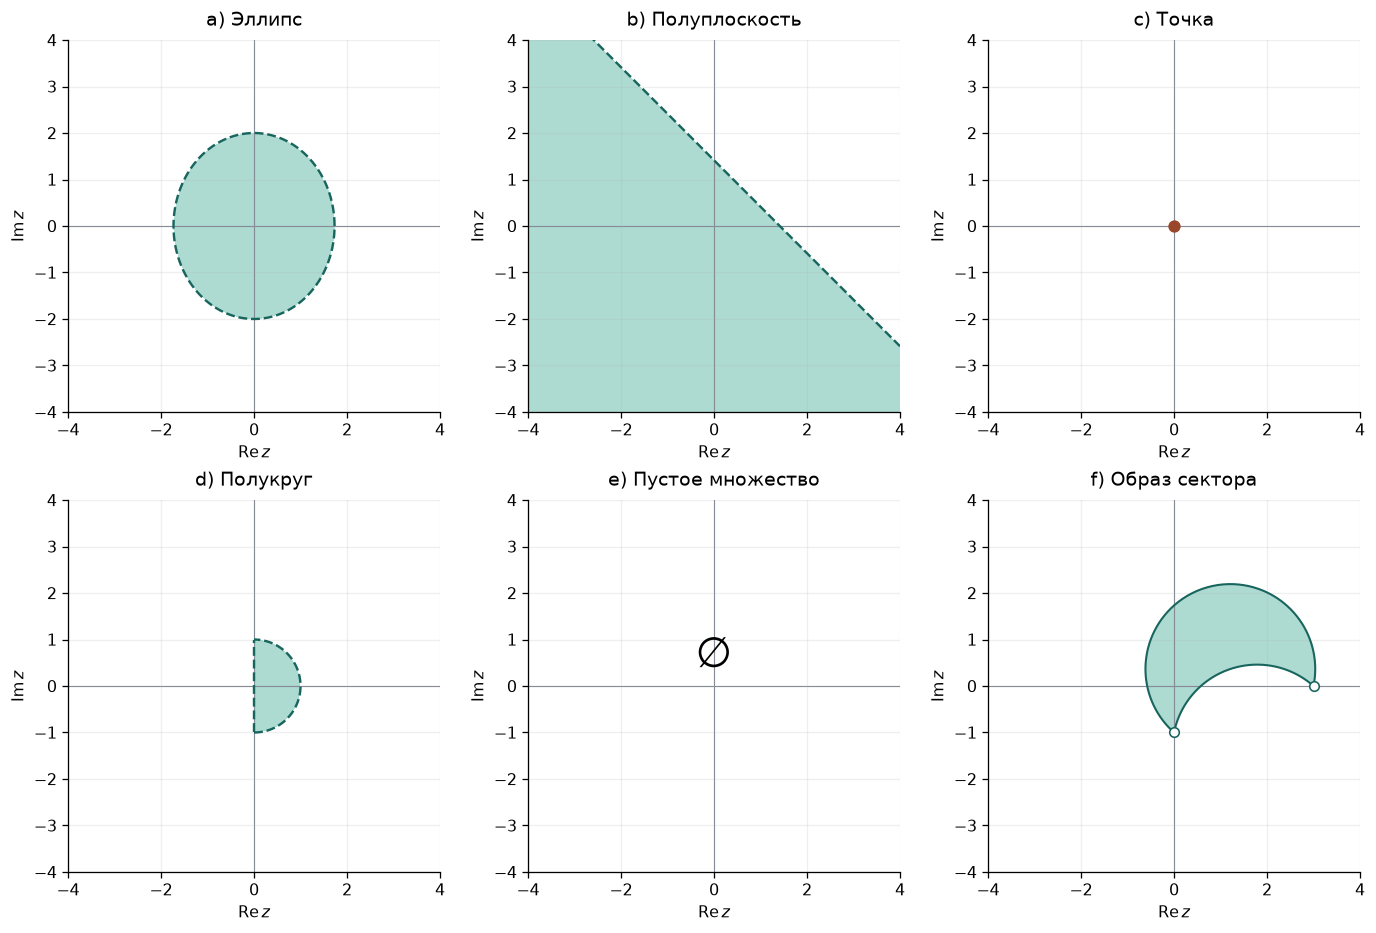

In [5]:
xy = np.linspace(-4, 4, 801)
x, y = np.meshgrid(xy, xy)
z = x + 1j*y
with np.errstate(divide="ignore", invalid="ignore"):
    phase_f = np.angle((3-z)/(z+1j))
f_region = ((phase_f >= -2*np.pi/3) & (phase_f <= -np.pi/3)
            & (z != 3) & (z != -1j))

fig, axes = plt.subplots(2, 3, figsize=(12, 8), layout="constrained")
titles = ["a) Эллипс", "b) Полуплоскость", "c) Точка",
          "d) Полукруг", "e) Пустое множество", "f) Образ сектора"]
masks = [x*x/3+y*y/4 < 1, x+y < np.sqrt(2), None,
         (x > 0) & (x*x+y*y < 1), None, f_region]
cmap = ListedColormap(["white", "#addbd2"])
for ax, title, mask in zip(axes.flat, titles, masks):
    plane(ax, title)
    ax.set(xlim=(-4, 4), ylim=(-4, 4))
    if mask is not None:
        ax.imshow(mask, extent=(-4, 4, -4, 4), origin="lower",
                  cmap=cmap, interpolation="nearest", zorder=0)

angle = np.linspace(0, 2*np.pi, 500)
axes[0, 0].plot(np.sqrt(3)*np.cos(angle), 2*np.sin(angle), "--", color=INK)
axes[0, 1].plot(xy, np.sqrt(2)-xy, "--", color=INK)
axes[0, 2].scatter(0, 0, color=ACCENT, s=45, zorder=3)
half = np.linspace(-np.pi/2, np.pi/2, 300)
axes[1, 0].plot(np.cos(half), np.sin(half), "--", color=INK)
axes[1, 0].plot([0, 0], [-1, 1], "--", color=INK)
axes[1, 1].text(0, 0.4, r"$\varnothing$", fontsize=26, ha="center")
radial = np.geomspace(1e-6, 1e6, 1500)
for theta in [-2*np.pi/3, -np.pi/3]:
    w = radial*np.exp(1j*theta)
    arc = (3-1j*w)/(1+w)
    axes[1, 2].plot(arc.real, arc.imag, color=INK, lw=1.3)
axes[1, 2].scatter([3, 0], [0, -1], facecolors="white",
                   edgecolors=INK, zorder=5)
plt.show()

## 2.5*. Уравнение окружности

Выделим полный квадрат:
$$
A|z|^2+\overline Bz+B\overline z+C
  =A\left|z+\frac BA\right|^2+C-\frac{|B|^2}{A}.
$$
Поэтому центр $z_0=-B/A$, а радиус $r=\sqrt{|B|^2-AC}/A$. Условия $A>0$ и $AC<|B|^2$ дают $r>0$.

## 2.6. Корни многочлена степени 11

В массиве коэффициентов оставляем нули на местах пропущенных степеней многочлена $x^{11}+x^{10}+x^8-2x^7-x^5+x^4+2x^2+2x+2$. После расчёта подставляем каждый корень обратно в многочлен.

In [6]:
coefficients = [1, 1, 0, 1, -2, 0, -1, 1, 0, 2, 2, 2]
roots = np.sort_complex(np.roots(coefficients))
residual = np.max(np.abs(np.polyval(coefficients, roots)))
for k, root in enumerate(roots, 1):
    print(f"z{k:02} = {complex_text(root, 10)}")
print(f"\nСумма модулей = {sum(abs(roots)):.10f}")
print(f"Максимальная действительная часть = {max(roots.real):.10f}")
print(f"Максимум |p(zₖ)| = {residual:.2e}")
assert len(roots) == 11 and residual < 1e-9

z01 = -1.7767690249+0.0000000000i
z02 = -0.7074344552-0.4643747259i
z03 = -0.7074344552+0.4643747259i
z04 = -0.4500371127-0.8039231442i
z05 = -0.4500371127+0.8039231442i
z06 = -0.0125001806-1.1826990817i
z07 = -0.0125001806+1.1826990817i
z08 = 0.4777545236-0.9010752305i
z09 = 0.4777545236+0.9010752305i
z10 = 1.0806017374-0.3238931188i
z11 = 1.0806017374+0.3238931188i

Сумма модулей = 11.9733844697
Максимальная действительная часть = 1.0806017374
Максимум |p(zₖ)| = 1.65e-12


## 2.7. Обобщённый биномиальный коэффициент

$$
C_z^w=\frac{\Gamma(z+1)}{\Gamma(w+1)\,\Gamma(z-w+1)}.
$$
В пунктах a–b берём $z=1+i$, $w=1-i$. В пункте c показатель зависит от точки плоскости, $w=1/z$. Аргумент вычисляем как приведённую к интервалу $(-\pi,\pi]$ мнимую часть логарифма отношения гамма-функций. Точки, в которых формула или аргумент не определены, пропускаем. Для линий уровня используем нули $\sin(\arg C_z^{1/z}-\theta)$ со $\cos(\arg C_z^{1/z}-\theta)>0$. Это отбирает фазу $\theta$ по модулю $2\pi$.

a) C = 4.36744914+4.85162977i
b) Arg(C) = 0.83786937 рад = 48.00638°


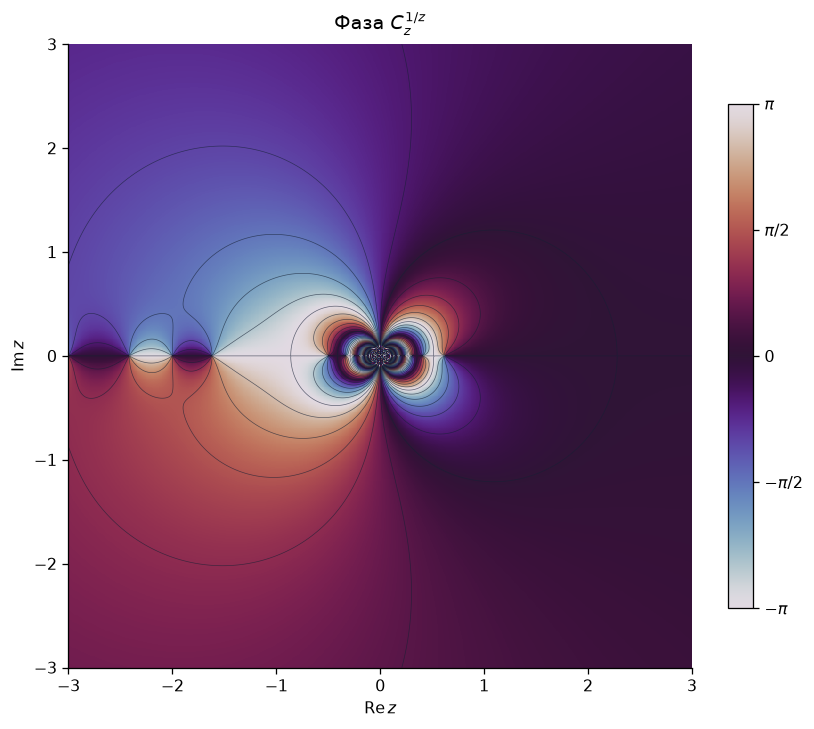

In [7]:
def log_binomial(z, w):
    return loggamma(z+1) - loggamma(w+1) - loggamma(z-w+1)

value = np.exp(log_binomial(1+1j, 1-1j))
phase = np.angle(value)
print(f"a) C = {complex_text(value)}")
print(f"b) Arg(C) = {phase:.8f} рад = {np.degrees(phase):.5f}°")
assert abs(value - (4.36745+4.85163j)) < 8e-6
assert abs(phase - 0.837869) < 8e-7

axis = np.linspace(-3, 3, 701)
x, y = np.meshgrid(axis, axis)
z = x + 1j*y
with np.errstate(invalid="ignore", divide="ignore"):
    phase_map = np.angle(np.exp(1j*log_binomial(z, 1/z).imag))
phase_map = np.ma.masked_invalid(phase_map)

fig, ax = plt.subplots(figsize=(7, 6.2), layout="constrained")
background = ax.pcolormesh(x, y, phase_map, shading="auto",
                           cmap="twilight", vmin=-np.pi, vmax=np.pi)
for theta in np.linspace(-np.pi, np.pi, 12, endpoint=False):
    offset = phase_map-theta
    lines = np.ma.masked_where(np.cos(offset) <= 0, np.sin(offset))
    ax.contour(x, y, lines, levels=[0], colors="#152034",
               linewidths=0.43, alpha=0.65)
ax.set(title=r"Фаза $C_z^{1/z}$", xlabel=r"$\operatorname{Re}z$",
       ylabel=r"$\operatorname{Im}z$", aspect="equal")
cb = fig.colorbar(background, ax=ax, shrink=0.8)
cb.set_ticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
cb.set_ticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
plt.show()

## 2.8. Определитель $A+\lambda I$

Корни из единицы степени 14 имеют аргументы $2\pi k/14$. В верхней полуплоскости максимум косинуса достигается при $k=1$, поэтому $\lambda=e^{i\pi/7}$. Для $A=\begin{pmatrix}7&5\\6&2\end{pmatrix}$
$$
\det(A+\lambda I)=(7+\lambda)(2+\lambda)-30=\lambda^2+9\lambda-16.
$$
Действительная часть равна $\cos(2\pi/7)+9\cos(\pi/7)-16$. Мнимая часть равна $\sin(2\pi/7)+9\sin(\pi/7)$.

In [8]:
lam = np.exp(1j*np.pi/7)
determinant = lam**2 + 9*lam - 16
assert np.isclose(determinant, np.linalg.det(np.array([[7, 5], [6, 2]]) + lam*np.eye(2)))
print(f"Re det = {determinant.real:.10f}")
print(f"Im det = {determinant.imag:.10f}")

Re det = -7.2677903870
Im det = 4.6867851345


## 2.9*. Множества Жюлиа

Для $f_c(z)=z^2+c$ множество Жюлиа проходит по границе между ограниченными орбитами и орбитами, уходящими на бесконечность. На сетке считаем шаг, на котором $|z|$ впервые превышает 2. Для обоих заданных $c$ выполняется $|c|<2$. Поэтому после выхода за этот радиус модуль продолжит расти. Рисунок показывает приближение на конечной сетке за ограниченное число шагов.

Материалы из задания. [Множество Жюлиа](https://ru.wikipedia.org/wiki/Множество_Жюлиа) · [Пример реализации на Python](https://blbadger.github.io/julia-sets#julia-sets-are-fractals)

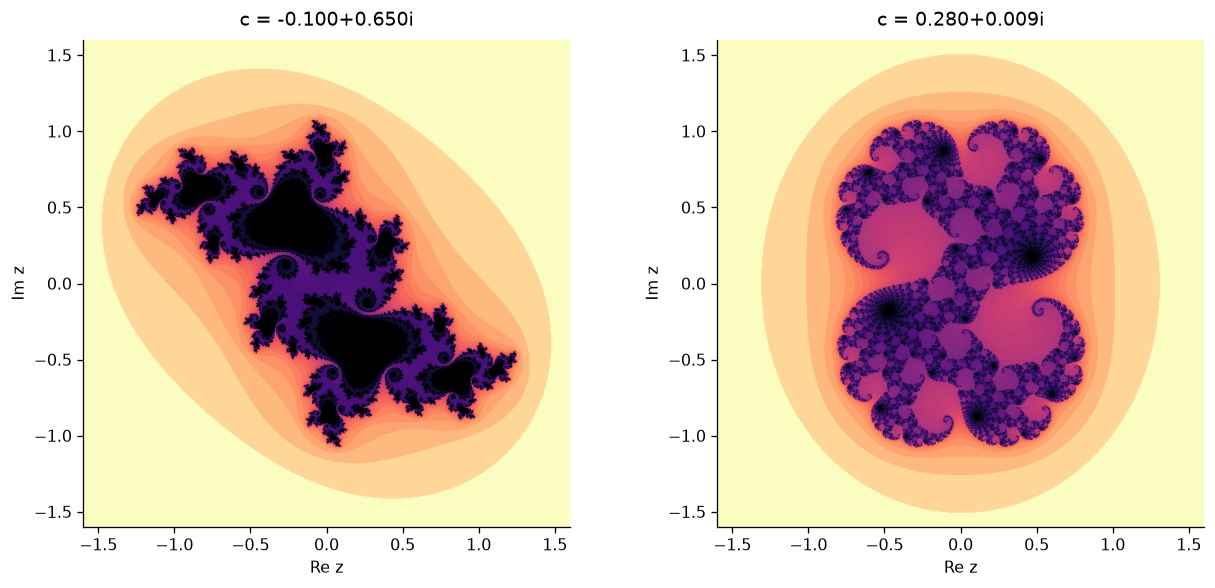

In [9]:
def escape_steps(c, width=650, steps=240, radius=1.6):
    axis = np.linspace(-radius, radius, width)
    values = (axis[None, :] + 1j*axis[:, None]).ravel()
    pending = np.arange(values.size)
    escaped = np.full(values.size, steps + 1, dtype=np.int16)
    for step in range(1, steps + 1):
        values = values*values + c
        outside = np.abs(values) > 2
        escaped[pending[outside]] = step
        pending, values = pending[~outside], values[~outside]
        if values.size == 0:
            break
    return escaped.reshape(width, width), (-radius, radius, -radius, radius)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, c in zip(axes, [-0.1+0.65j, 0.28+0.009j]):
    steps, extent = escape_steps(c)
    ax.imshow(np.log1p(steps), origin="lower", extent=extent, cmap="magma_r")
    ax.set(title=f"c = {complex_text(c, 3)}", xlabel="Re z", ylabel="Im z")
plt.show()

Для рациональных отображений решаем $w=f(z)$ и строим цепочки обратных образов. Для $f(z)=(iz^5-1)/(z^5-i)$ берём все пятые корни из $(iw-1)/(w-i)$. Для $f(z)=(z^2+i)/(1-z^2)$ берём оба квадратных корня из $(w-i)/(w+1)$. На каждом шаге случайно выбираем один из корней. После 70 начальных шагов сохраняем точки и строим численное приближение. Фиксированное зерно генератора делает результат воспроизводимым.

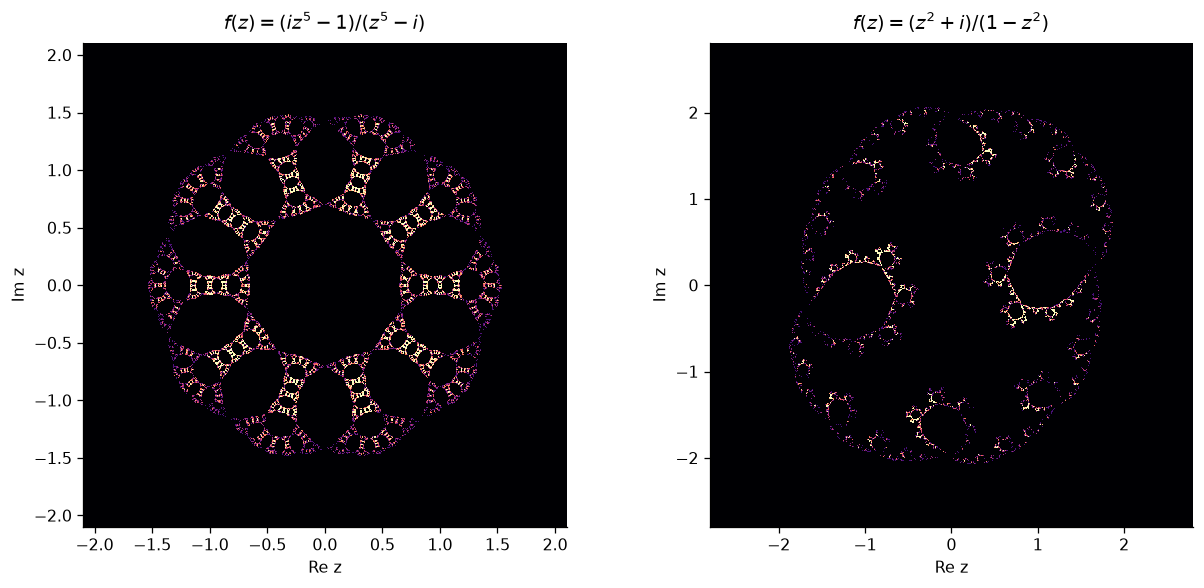

In [10]:
def inverse_sample(power, preimage_power, seed, chains=500, samples=450):
    rng = np.random.default_rng(seed)
    w = 0.23 + 0.11j + 0.01*(rng.normal(size=chains) + 1j*rng.normal(size=chains))
    branches = np.exp(2j*np.pi*np.arange(power)/power)
    saved = np.empty((samples, chains), dtype=complex)
    warmup = 70
    for step in range(warmup + samples):
        main_root = np.power(preimage_power(w), 1/power)
        w = main_root * branches[rng.integers(power, size=chains)]
        if step >= warmup:
            saved[step-warmup] = w
    return saved.ravel()

def first_power(w):
    return (1j*w-1)/(w-1j)

def second_power(w):
    return (w-1j)/(w+1)

test = complex(0.23, 0.11)
z1 = nth_roots(first_power(test), 5)
z2 = nth_roots(second_power(test), 2)
assert np.allclose((1j*z1**5-1)/(z1**5-1j), test)
assert np.allclose((z2**2+1j)/(1-z2**2), test)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
configs = [
    (5, first_power, r"$f(z)=(iz^5-1)/(z^5-i)$", 2.1),
    (2, second_power, r"$f(z)=(z^2+i)/(1-z^2)$", 2.8),
]
for index, (ax, (power, preimage, title, limit)) in enumerate(zip(axes, configs)):
    cloud = inverse_sample(power, preimage, seed=31+index)
    assert np.isfinite(cloud).all()
    density, re, im = np.histogram2d(
        cloud.real, cloud.imag, bins=720, range=[[-limit, limit]]*2
    )
    log_density = np.log1p(density.T)
    upper = np.quantile(log_density[log_density > 0], 0.85)
    ax.imshow(log_density, extent=(re[0], re[-1], im[0], im[-1]),
              origin="lower", cmap="magma", vmax=upper, interpolation="nearest")
    ax.set(title=title, xlabel="Re z", ylabel="Im z")
plt.show()

## 2.10*. Кривые на сфере Римана

Для $z=x+iy$ точка на единичной сфере имеет координаты
$$
X=\frac{2x}{1+|z|^2},\qquad Y=\frac{2y}{1+|z|^2},
\qquad Z=\frac{|z|^2-1}{1+|z|^2}.
$$
Подстановка даёт $X^2+Y^2+Z^2=1$. Бесконечно удалённой точке соответствует северный полюс $(0,0,1)$. Для рисунков параметры выбираем сами. Используем прямую $y=0.5x+0.5$, окружность $|z-0.45|=1.2$, параболу $y=0.55x^2$ и обе ветви гиперболы $x^2-y^2=1$.

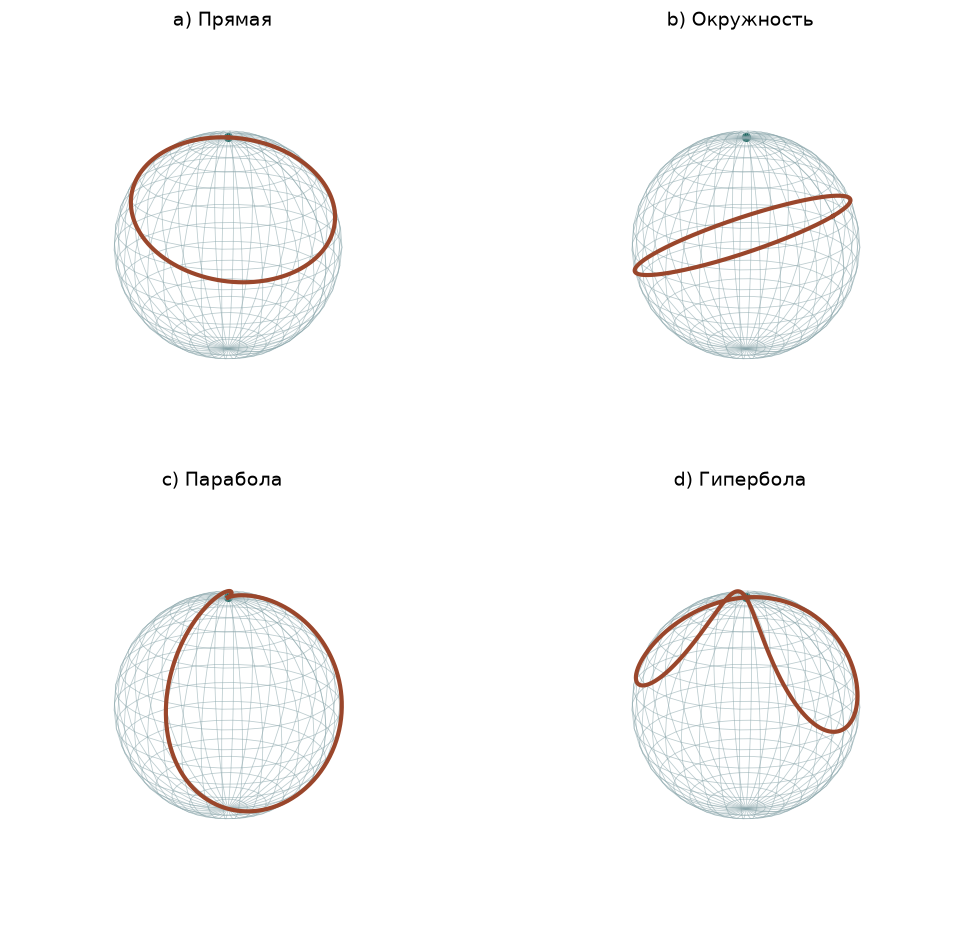

In [11]:
def stereographic(z):
    r2 = abs(z)**2
    denominator = 1 + r2
    return np.array([2*z.real/denominator, 2*z.imag/denominator,
                     (r2-1)/denominator])

NORTH = np.array([[0.0], [0.0], [1.0]])
u, v = np.meshgrid(np.linspace(0, 2*np.pi, 37), np.linspace(0, np.pi, 19))

def draw_sphere(ax, curves, title, reaches_north=False):
    ax.plot_wireframe(np.cos(u)*np.sin(v), np.sin(u)*np.sin(v), np.cos(v),
                      color="#8ba7ac", alpha=0.58, lw=0.5)
    for curve in curves:
        points = stereographic(curve)
        assert np.allclose(np.sum(points**2, axis=0), 1)
        if reaches_north:
            points = np.concatenate([NORTH, points, NORTH], axis=1)
        ax.plot(*points, color=ACCENT, lw=2.6, zorder=5)
    ax.scatter(*NORTH[:, 0], color=INK, s=22, depthshade=False)
    ax.set(title=title, xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), zlim=(-1.1, 1.1))
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=22, azim=-57)
    ax.set_axis_off()

t = np.sinh(np.linspace(-6, 6, 1400))
h = np.linspace(-7, 7, 1400)
theta = np.linspace(0, 2*np.pi, 800)
choices = [
    ("a) Прямая", [t + 1j*(0.5*t+0.5)], True),
    ("b) Окружность", [0.45 + 1.2*np.exp(1j*theta)], False),
    ("c) Парабола", [t + 0.55j*t*t], True),
    ("d) Гипербола", [sign*np.cosh(h)+1j*np.sinh(h) for sign in (-1, 1)], True),
]
fig = plt.figure(figsize=(9, 8), layout="constrained")
for index, (title, curves, reaches_north) in enumerate(choices, 1):
    draw_sphere(fig.add_subplot(2, 2, index, projection="3d"),
                curves, title, reaches_north)
plt.show()

## 2.10*. Логарифмическая спираль

Используем $z(\varphi)=ae^{b\varphi}e^{i\varphi}$ и ту же проекцию на сферу. Выбираем $a=1$, $b=0.19$. При $\varphi\to-\infty$ радиус стремится к нулю и спираль приближается к южному полюсу. При $\varphi\to+\infty$ радиус растёт и витки приближаются к северному полюсу.

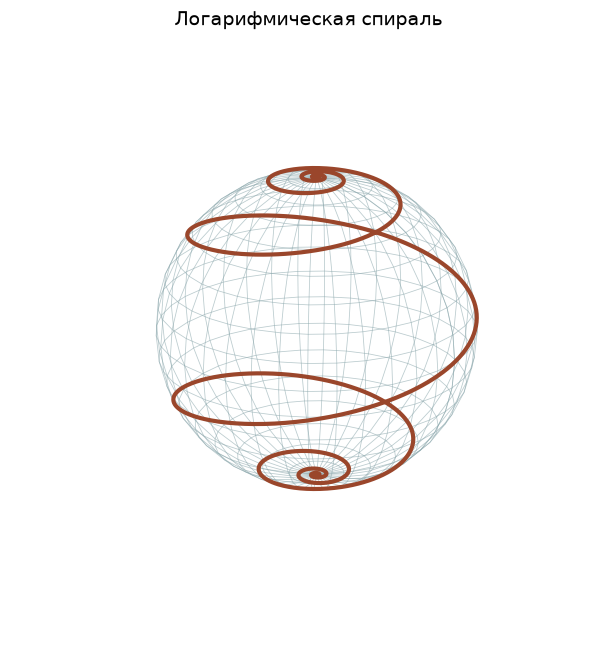

In [12]:
a, b = 1, 0.19
phi = np.linspace(-9*np.pi, 9*np.pi, 2500)
spiral = a*np.exp(b*phi + 1j*phi)
fig = plt.figure(figsize=(6.2, 5.5), layout="constrained")
draw_sphere(fig.add_subplot(projection="3d"), [spiral], "Логарифмическая спираль")
plt.show()